<a href="https://colab.research.google.com/github/aryanshenoy02/Banking-Fraud-Detection/blob/main/notebooks/autoencoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

# uploaded is a dict like {'whatever_name.csv': b'...bytes...'}
# next(iter(...)) grabs the first (and only) key, i.e. the filename
filename = next(iter(uploaded))

try:
    # Skipping the first 3 rows of metadata to start directly from the table headers
    df = pd.read_csv(filename, skiprows=3)
    print(f"Successfully loaded '{filename}' by skipping the metadata rows:")
    display(df.head(10))
except Exception as e:
    print(f"Error reading CSV: {e}")

Saving AnanthTransactions.csv to AnanthTransactions (1).csv
Successfully loaded 'AnanthTransactions (1).csv' by skipping the metadata rows:


,Date,Time,Transaction Details,Transaction ID,UTR,Transaction Type,Credit/debit instrument,Amount
0,"Nov 15, 2026",09:28 am,Refund from MEESHO TECHNOLOGIES PRIVATE LIMITED,T2611150928583970026505,7.467606e+11,CREDIT,Credited to 356129XXXXXXXX56,231.0
1,"Nov 14, 2026",08:32 pm,Paid to GREEN LEAF PHARMA,T2611142032375092460404,7.385491e+11,DEBIT,Paid by XXXXXXXXXX35,2485.0
2,"Nov 14, 2026",01:16 pm,Paid to P KS PLATAINMERCHANT,T2611141316165137506392,3.398093e+11,DEBIT,Paid by 652926XXXXXXXX08,280.0
3,"Nov 14, 2026",12:58 pm,Paid to RELIANCE IRRIGATION SYSTEMS,T2611141258095590097590,6.687164e+11,DEBIT,Paid by XXXXXXXXXX35,900.0
4,"Nov 13, 2026",09:45 pm,Paid to Jio Prepaid Recharges,T2611132144569165871829,7.333325e+10,DEBIT,Paid by 356129XXXXXXXX56,100.0
5,"Nov 13, 2026",12:37 pm,Paid to KEDINJE TRADERS,T2611131237378245505225,9.967444e+11,DEBIT,Paid by XXXXXXXXXX35,18370.0
6,"Nov 13, 2026",10:08 am,Paid to VRL LOGISTICS LTD - KRK,T2611131008428510647767,5.000732e+11,DEBIT,Paid by XXXXXXXXXX35,560.0
7,"Nov 11, 2026",11:50 am,Paid to MEESHO TECHNOLOGIES PRIVATE LIMITED,T2611111150351895593924,7.467606e+11,DEBIT,Paid by 356129XXXXXXXX56,231.0
8,"Nov 10, 2026",04:44 pm,Paid to MEESHO TECHNOLOGIES PRIVATE LIMITED,T2611101644264331863931,4.915829e+11,DEBIT,Paid by 356129XXXXXXXX56,183.0
9,"Nov 10, 2026",01:46 pm,Paid to ASHRAYA MEDICALS,T2611101346250840905499,3.384807e+11,DEBIT,Paid by 356129XXXXXXXX56,180.0


In [3]:
combined = df['Date'].astype(str) + ' ' + df['Time'].astype(str)


parsed = pd.to_datetime(
    combined.str.replace(r'\bSept\b', 'Sep', regex=True),
    format='%b %d, %Y %I:%M %p', #example - November 15, 2026 09:30 AM
    errors='coerce' #to replace unparseable data with NaT (Not a Time)
)

invalid_rows = df[parsed.isna()]

display(invalid_rows)

#boolean filtering to remove the invalid rows
df = df[parsed.notna()].copy()
#creating Datetime with no NaN values
df['Datetime'] = parsed[parsed.notna()]

,Date,Time,Transaction Details,Transaction ID,UTR,Transaction Type,Credit/debit instrument,Amount
628,This is an automatically generated statement. ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
629,of any errors in the statement at https://supp...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
630,terms-conditions/ for PhonePe Terms & Conditio...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
631,Disclaimer : Do not fall prey to fictitious of...,money circulation schemes and cheap funds,NaN,NaN,NaN,NaN,NaN,NaN
632,etc. through SMS,emails and calls. The contents of this email ...,NaN,NaN,NaN,NaN,NaN,NaN
633,the recipient specified in this document. If y...,please inform PhonePe at,NaN,NaN,NaN,NaN,NaN,NaN
634,https://support.phonepe.com/statement so that ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

# 1. Drop rows where all columns are NaN (if any exist at the end of the file)
df = df.dropna(how='all').copy()

# 2. Clean the 'Transaction Details' column
# We remove case-insensitive variations of "Paid to " and "Received from "
df['Transaction Details'] = df['Transaction Details'].str.replace(r'^(Paid to|Received from)\s+', '', case=False, regex=True)

# Sort chronologically so we can calculate the time difference forward in time
df = df.sort_values('Datetime').reset_index(drop=True)

# 4. Calculate the time difference between consecutive transactions (in hours)
df['Time_Diff_Hours'] = df['Datetime'].diff().dt.total_seconds() / 3600.0
df['Time_Diff_Hours'] = df['Time_Diff_Hours'].fillna(0)

# Display the cleaned and processed DataFrame
display(df[['Transaction Details', 'Transaction Type', 'Amount', 'Time_Diff_Hours']].head(10))

,Transaction Details,Transaction Type,Amount,Time_Diff_Hours
0,Harsha Refreshment,DEBIT,120.0,0.000000
1,RAJESH SHETTY,DEBIT,730.0,2.366667
2,VARASIDDHI VINAYAKA ENTERPRISES,DEBIT,135.0,66.633333
3,MATHAJI ELECTRICALS,DEBIT,220.0,0.150000
4,Subramanya Acharya Belman,DEBIT,500.0,5.050000
5,MAHENDRA SINGH,DEBIT,90.0,26.733333
6,AMRUTHA CANTEEN,DEBIT,40.0,18.266667
7,Janaushadi Medical,DEBIT,140.0,0.033333
8,B N D SHENOY AND CO,DEBIT,2813.0,0.083333
9,RAJESHKUMAR MAHADAV MISHRA,DEBIT,60.0,3.900000


In [5]:
import numpy as np

df['Counterparty_Transaction_Count'] = df.groupby('Transaction Details').cumcount()
df['hour'] = df['Datetime'].dt.hour
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['dayofweek'] = df['Datetime'].dt.dayofweek
df['is_new_counterparty'] = (df['Counterparty_Transaction_Count'] == 0).astype(int)
df['is_debit'] = (df['Transaction Type'] == 'DEBIT').astype(int)

In [6]:
import re

def is_known_merchant(name):
    # Strip whitespace
    name = str(name).strip()

    # Pattern: looks like a raw ID — e.g. KA01AR2800
    # Characteristics: no spaces, mix of uppercase letters and digits, length < 15
    raw_id_pattern = r'^[A-Z0-9]{5,15}$'

    if re.match(raw_id_pattern, name):
        return 0  # Unknown — raw ID
    else:
        return 1  # Known — readable merchant name

df['is_known_merchant'] = df['Transaction Details'].apply(is_known_merchant)

In [7]:
df_ = df.drop(columns = ['Date','Time','Transaction ID','UTR','Transaction Type','Credit/debit instrument','Datetime','hour','Transaction Details'])

In [8]:
from sklearn.preprocessing import MinMaxScaler

cols_to_scale = ['Amount', 'Time_Diff_Hours', 'Counterparty_Transaction_Count']

scaler = MinMaxScaler()
df_[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

In [9]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras import layers

class AnomalyDetector(Model):
  def __init__(self):
    super(AnomalyDetector, self).__init__()
    self.encoder = tf.keras.Sequential([
        layers.Dense(16, activation='relu'),
        layers.Dense(8, activation='relu'),
        layers.Dense(4, activation='relu')
    ])

    self.decoder = tf.keras.Sequential([
        layers.Dense(8, activation='relu'),
        layers.Dense(16, activation='relu'),
        layers.Dense(input_dim, activation='linear')
    ])

  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded

input_dim = df_.shape[1]
autoencoder = AnomalyDetector()
autoencoder.compile(optimizer='adam', loss='mse')

history = autoencoder.fit(
    df_, df_,
    epochs=50,
    batch_size=32,
    shuffle=True,
)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 2.0001
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.7220 
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.2248 
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6082 
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2329
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1883
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1793
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1745
Epoch 9/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1689
Epoch 10/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1616
Epoch 11/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1491
Epoch 12/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1379
Epoch 13/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1290
Epoch 14/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1228
Epoch 15/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1184
Epoch 16/50
20/2

In [10]:
import numpy as np

# Get reconstructed output
reconstructions = autoencoder.predict(df_)

# Calculate MSE per transaction (mean across all 9 features)
mse = np.mean(np.power(df_ - reconstructions, 2), axis=1)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [11]:
threshold = np.percentile(mse, 99)  # top 1% flagged as anomalies
print(f"Threshold: {threshold:.4f}")

df['reconstruction_error'] = mse
df['is_anomaly'] = (mse > threshold).astype(int)

# See what got flagged
print(df[df['is_anomaly'] == 1][['Transaction Details', 'Amount', 'reconstruction_error']].sort_values('reconstruction_error', ascending=False))

Threshold: 0.2143
       Transaction Details  Amount  reconstruction_error
500                  KIRAN  2000.0              0.338747
454            Padav Haris    10.0              0.274564
181              BADRUDDIN  2000.0              0.241462
148                SANDHYA  2320.0              0.236234
437    SACHIDANANDA SHENOY  1200.0              0.234578
496          Jyothi Shenoy     1.0              0.226359
623  Jio Prepaid Recharges   100.0              0.214606


In [12]:
def compute_trust_multiplier(row, contacts):
    multiplier = 1.0

    # Known contact — strong trust signal
    if row['Transaction Details'] in contacts:
        multiplier *= 0.5

    if row['Transaction Details'] in known_corp:
        multiplier *= 0.8

    # Known merchant — moderate trust signal
    if row['is_known_merchant'] == 1:
        multiplier *= 0.7

    return multiplier

known_corp = [
    "AMAZON"
]
contacts = [
    "BHOOMIKA SRIDHAR",
    "NAGARAJU",
    "Mr Yuvan R",
    "BirthGiver(Amma)",
    "SWIGGY",
    "MYNTRA"
    ""
]

df['trust_multiplier'] = df.apply(
    lambda row: compute_trust_multiplier(row, contacts), axis=1
)

df['final_anomaly_score'] = df['reconstruction_error'] * df['trust_multiplier']

# Reapply threshold on final score
threshold_final = np.percentile(df['final_anomaly_score'], 90)
df['is_anomaly'] = (df['final_anomaly_score'] > threshold_final).astype(int)
print(df[df['is_anomaly'] == 1][['Transaction Details', 'Amount', 'reconstruction_error']].sort_values('reconstruction_error', ascending=False))

     Transaction Details  Amount  reconstruction_error
500                KIRAN  2000.0              0.338747
454          Padav Haris    10.0              0.274564
181            BADRUDDIN  2000.0              0.241462
148              SANDHYA  2320.0              0.236234
437  SACHIDANANDA SHENOY  1200.0              0.234578
..                   ...     ...                   ...
507         Manjunatha V    70.0              0.122454
339              DILKUSH   210.0              0.120666
193          BHARATHAMMA   100.0              0.119446
194             SRINIVAS    60.0              0.119444
132           HARIPRASAD   150.0              0.115966

[63 rows x 3 columns]


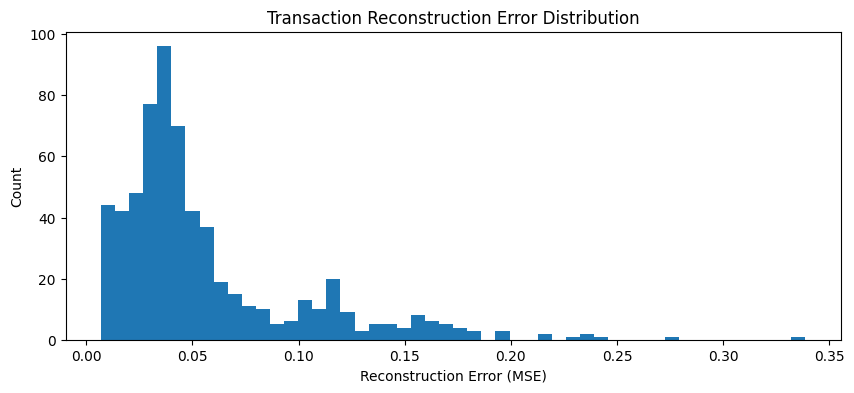

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.hist(mse, bins=50)
plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Count')
plt.title('Transaction Reconstruction Error Distribution')
plt.show()

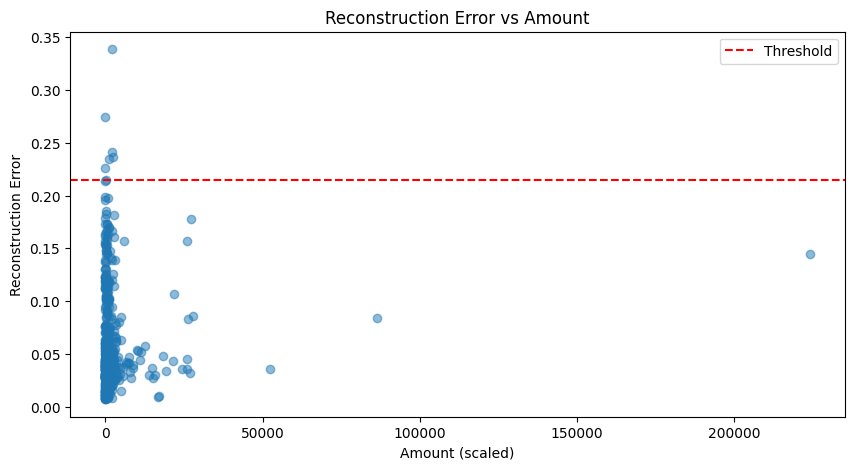

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.scatter(df['Amount'], df['reconstruction_error'], alpha=0.5)
plt.axhline(y=threshold, color='red', linestyle='--', label='Threshold')
plt.xlabel('Amount (scaled)')
plt.ylabel('Reconstruction Error')
plt.title('Reconstruction Error vs Amount')
plt.legend()
plt.show()

In [21]:
def screen_transaction(new_row, df, autoencoder, scaler, contacts, threshold):
    """
    new_row: dict with raw transaction values
    Returns: the row with anomaly score and label appended
    """
    import pandas as pd
    import numpy as np

    threshold = 0.49

    # Step 1 — convert to dataframe
    new_df = pd.DataFrame([new_row])

    # Step 2 — feature engineering (same as training)
    new_df['hour'] = pd.to_datetime(new_df['Datetime']).dt.hour
    new_df['hour_sin'] = np.sin(2 * np.pi * new_df['hour'] / 24)
    new_df['hour_cos'] = np.cos(2 * np.pi * new_df['hour'] / 24)
    new_df['dayofweek'] = pd.to_datetime(new_df['Datetime']).dt.dayofweek
    new_df['is_known_merchant'] = new_df['Transaction Details'].apply(is_known_merchant)
    new_df['is_debit'] = (new_df['Transaction Type'] == 'DEBIT').astype(int)

    # Step 3 — drop columns not used in training
    feature_cols = [
        'Amount', 'Time_Diff_Hours', 'Counterparty_Transaction_Count',
        'hour_sin', 'hour_cos', 'dayofweek',
        'is_new_counterparty', 'is_debit', 'is_known_merchant'
    ]
    new_df = new_df[feature_cols]

    # Step 4 — scale using the SAME scaler
    cols_to_scale = ['Amount', 'Time_Diff_Hours', 'Counterparty_Transaction_Count']
    new_df[cols_to_scale] = scaler.transform(new_df[cols_to_scale])

    # Step 5 — get reconstruction error
    reconstruction = autoencoder.predict(new_df, verbose=0)
    error = np.mean(np.power(new_df.values - reconstruction, 2), axis=1)[0]

    # Step 6 — apply trust multiplier
    multiplier = compute_trust_multiplier(
        {'Transaction Details': new_row['Transaction Details'],
         'is_known_merchant': new_df['is_known_merchant'].values[0]},
        contacts
    )
    final_score = error * multiplier

    # Step 7 — label
    is_anomaly = int(final_score > threshold)

    print(f"Reconstruction Error : {error:.4f}")
    print(f"Trust Multiplier     : {multiplier}")
    print(f"Final Anomaly Score  : {final_score:.4f}")
    print(f"Threshold            : {threshold:.4f}")
    print(f"Label                : {'🚨 ANOMALY' if is_anomaly else '✅ NORMAL'}")

    return is_anomaly


new_transaction = {
    'Transaction Details': 'AMAZON',
    'Transaction Type': 'DEBIT',
    'Amount': 499999.00,
    'Datetime': '2026-11-18 02:15:00',  # 2am — suspicious
    'Time_Diff_Hours': 0.5,
    'Counterparty_Transaction_Count': 5,
    'is_new_counterparty': 1,
}

result = screen_transaction(
    new_transaction, df, autoencoder, scaler, contacts, threshold_final
)

Reconstruction Error : 0.9732
Trust Multiplier     : 0.8
Final Anomaly Score  : 0.7785
Threshold            : 0.4900
Label                : 🚨 ANOMALY
